<a href="https://colab.research.google.com/github/Xyrfo/Pembelajaran-Mesin/blob/main/JS10/tugas_lab_js10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Lab JS10 - Klasifikasi MNIST dengan ANN

**Nama:** Rifo Anggi Barbara Danuarta  
**NIM:** 244107020063  
**Kelas:** 3F  



## Alur Pengerjaan

1. Load dan eksplorasi MNIST.
2. Normalisasi piksel dan pembagian data train/validation/test.
3. Perbandingan fitur raw pixel, PCA, dan HOG.
4. Perbandingan beberapa arsitektur ANN.
5. Perbandingan aktivasi ReLU, tanh, dan sigmoid.
6. Training model final dan evaluasi lengkap.
7. Analisis kesalahan dan penyimpanan model.
8. **[TAMBAHAN]** Dropout, learning rate/batch size, ROC-AUC, ringkasan eksperimen, dan uji data bergeser/berotasi.


In [1]:
import os
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from skimage.feature import hog
from scipy.ndimage import shift, rotate

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SEED = 24
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))


TensorFlow: 2.21.0
GPU: []


In [2]:
def timer_start():
    return time.perf_counter()


def build_ann(input_dim, hidden=(256, 128), activation='relu', dropout=0.0, learning_rate=1e-3):
    model = keras.Sequential([layers.Input(shape=(input_dim,))])
    for units in hidden:
        model.add(layers.Dense(units, activation=activation))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(10, activation='softmax'))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model


def callbacks_for(patience=2):
    return [
        keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=patience, restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=1, min_lr=1e-6
        ),
    ]


def fit_model(Xtr, ytr, Xv, yv, hidden=(256, 128), activation='relu',
              dropout=0.0, epochs=12, batch_size=128, learning_rate=1e-3):
    tf.keras.backend.clear_session()
    model = build_ann(Xtr.shape[1], hidden, activation, dropout, learning_rate)
    started = timer_start()
    history = model.fit(
        Xtr, ytr,
        validation_data=(Xv, yv),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks_for(),
        verbose=0,
    )
    elapsed = time.perf_counter() - started
    best_epoch = int(np.argmin(history.history['val_loss']) + 1)
    return model, history, elapsed, best_epoch


def history_plot(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(history.history['accuracy'], label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Validation')
    axes[0].set_title(title + ' - Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()
    axes[1].plot(history.history['loss'], label='Train')
    axes[1].plot(history.history['val_loss'], label='Validation')
    axes[1].set_title(title + ' - Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()
    plt.tight_layout()
    plt.show()


## 1. Load Dataset MNIST dan EDA

MNIST berisi citra grayscale berukuran 28×28 dari digit 0 sampai 9. Karena output memiliki 10 kelas, layer output ANN menggunakan 10 neuron dengan aktivasi softmax.


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Data train asli: (60000, 28, 28) (60000,)
Data test asli : (10000, 28, 28) (10000,)
Rentang piksel : 0 - 255
Kelas          : [0 1 2 3 4 5 6 7 8 9]


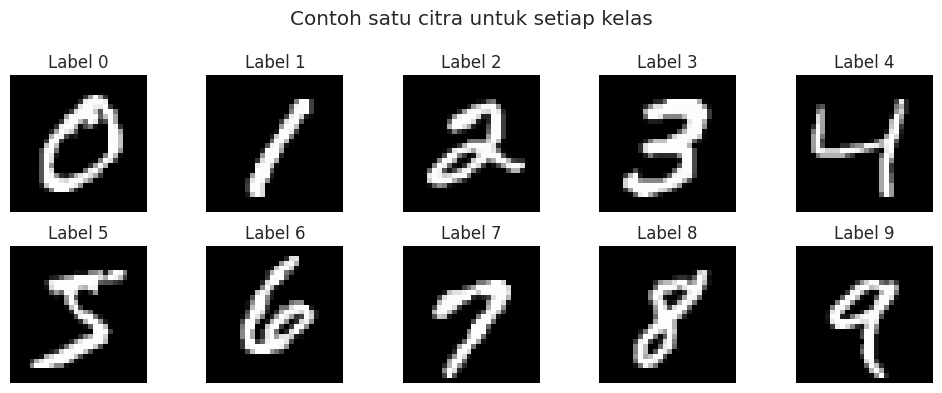

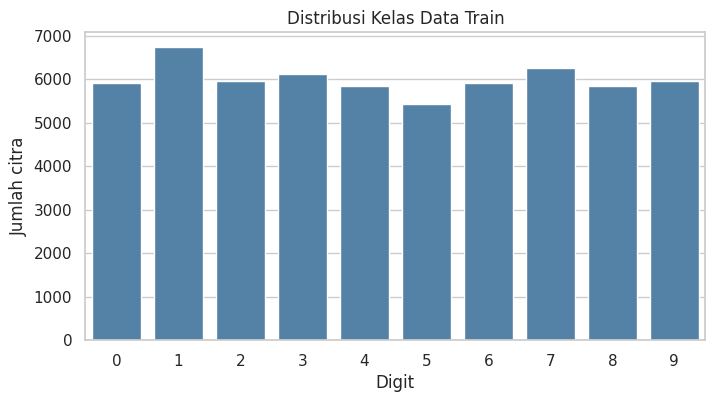

In [3]:
(X_all, y_all), (X_test_img, y_test) = keras.datasets.mnist.load_data()

print('Data train asli:', X_all.shape, y_all.shape)
print('Data test asli :', X_test_img.shape, y_test.shape)
print('Rentang piksel :', X_all.min(), '-', X_all.max())
print('Kelas          :', np.unique(y_all))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.ravel()):
    idx = np.where(y_all == digit)[0][0]
    ax.imshow(X_all[idx], cmap='gray')
    ax.set_title(f'Label {digit}')
    ax.axis('off')
plt.suptitle('Contoh satu citra untuk setiap kelas')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
counts = np.bincount(y_all, minlength=10)
sns.barplot(x=np.arange(10), y=counts, color='steelblue')
plt.title('Distribusi Kelas Data Train')
plt.xlabel('Digit')
plt.ylabel('Jumlah citra')
plt.show()


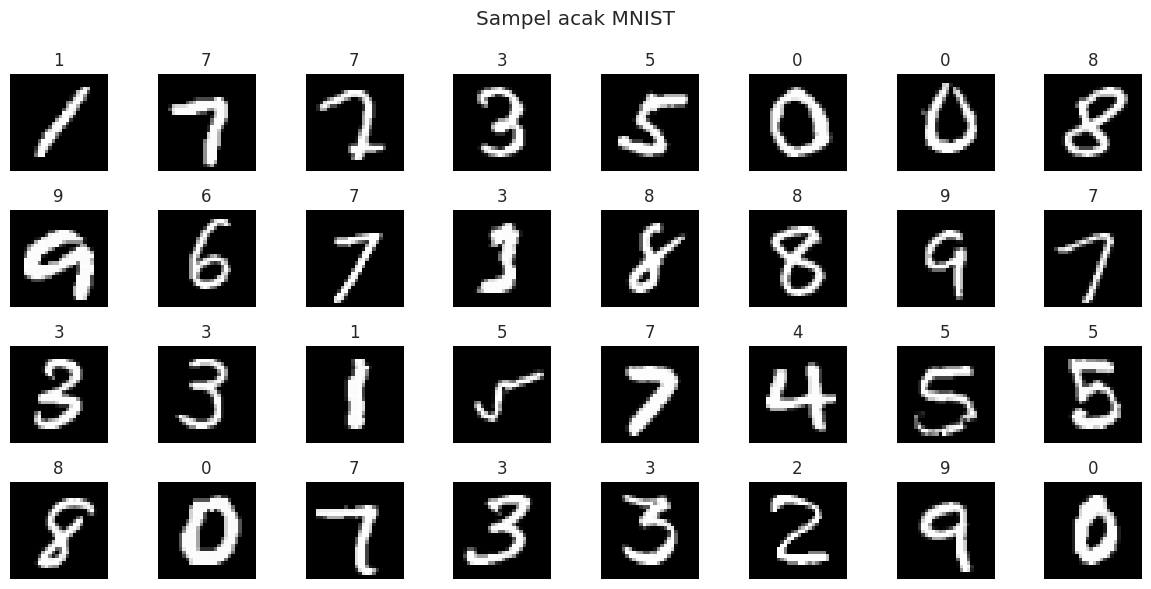

In [4]:
fig, axes = plt.subplots(4, 8, figsize=(12, 6))
sample_indices = np.random.default_rng(SEED).choice(len(X_all), 32, replace=False)
for ax, idx in zip(axes.ravel(), sample_indices):
    ax.imshow(X_all[idx], cmap='gray')
    ax.set_title(str(y_all[idx]))
    ax.axis('off')
plt.suptitle('Sampel acak MNIST')
plt.tight_layout()
plt.show()


## 2. Pra-pengolahan Data

Pra-pengolahan yang digunakan:

- Normalisasi piksel dari 0–255 menjadi 0–1 agar optimasi gradient descent lebih stabil.
- Flatten citra 28×28 menjadi 784 fitur untuk input ANN dense.
- Membagi data train menjadi 54.000 data training dan 6.000 data validation.
- Label tetap berupa integer sehingga dapat menggunakan `sparse_categorical_crossentropy` tanpa one-hot encoding tambahan.


In [5]:
X_train_img, X_val_img = X_all[:54000], X_all[54000:]
y_train, y_val = y_all[:54000], y_all[54000:]

X_train = X_train_img.astype('float32') / 255.0
X_val = X_val_img.astype('float32') / 255.0
X_test = X_test_img.astype('float32') / 255.0

X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

print('Train:', X_train_flat.shape, y_train.shape)
print('Val  :', X_val_flat.shape, y_val.shape)
print('Test :', X_test_flat.shape, y_test.shape)
print('Rentang setelah normalisasi:', X_train_flat.min(), '-', X_train_flat.max())


Train: (54000, 784) (54000,)
Val  : (6000, 784) (6000,)
Test : (10000, 784) (10000,)
Rentang setelah normalisasi: 0.0 - 1.0


## 3. Pemilihan Fitur

Tiga representasi dibandingkan dengan model ANN sederhana dan subset data yang sama:

1. **Raw pixel**: 784 fitur langsung dari citra.
2. **PCA**: mereduksi dimensi dengan mempertahankan 95% variasi data.
3. **HOG**: menangkap arah gradien/struktur bentuk digit

Perbandingan memakai 20.000 data training dan 2.000 data validation agar eksperimen tetap ringan di Colab. Model final nantinya memakai seluruh data training.


Raw pixel selesai: 0.9629999995231628
PCA selesai: 152 komponen


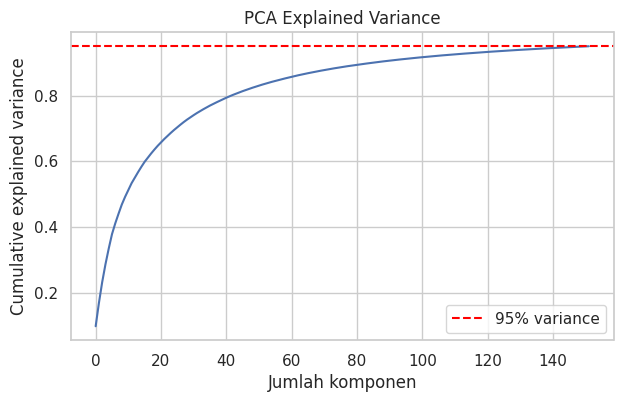

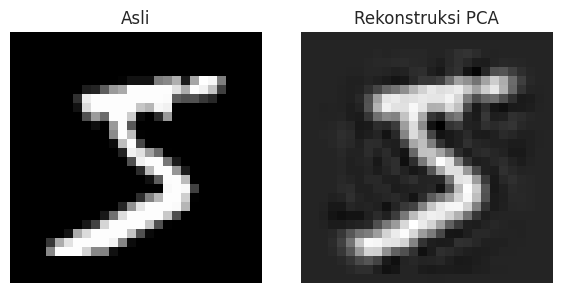

In [6]:
FEATURE_N = 20000
VAL_N = 2000
Xf_train = X_train_flat[:FEATURE_N]
yf_train = y_train[:FEATURE_N]
Xf_val = X_val_flat[:VAL_N]
yf_val = y_val[:VAL_N]

feature_results = []
feature_models = {}

start = timer_start()
raw_model, raw_history, raw_time, raw_epoch = fit_model(
    Xf_train, yf_train, Xf_val, yf_val, hidden=(128,), epochs=8
)
raw_val_acc = max(raw_history.history['val_accuracy'])
feature_results.append({
    'Fitur': 'Raw pixel', 'Dimensi': Xf_train.shape[1],
    'Val accuracy': raw_val_acc, 'Waktu (detik)': raw_time,
})
feature_models['Raw pixel'] = raw_model
print('Raw pixel selesai:', raw_val_acc)

start = timer_start()
pca = PCA(n_components=0.95, svd_solver='full', random_state=SEED)
Xf_train_pca = pca.fit_transform(Xf_train)
Xf_val_pca = pca.transform(Xf_val)
pca_time = time.perf_counter() - start
pca_model, pca_history, train_time, pca_epoch = fit_model(
    Xf_train_pca, yf_train, Xf_val_pca, yf_val, hidden=(128,), epochs=8
)
feature_results.append({
    'Fitur': 'PCA 95%', 'Dimensi': Xf_train_pca.shape[1],
    'Val accuracy': max(pca_history.history['val_accuracy']),
    'Waktu (detik)': pca_time + train_time,
})
feature_models['PCA 95%'] = pca_model
print('PCA selesai:', Xf_train_pca.shape[1], 'komponen')

plt.figure(figsize=(7, 4))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.axhline(0.95, color='red', linestyle='--', label='95% variance')
plt.xlabel('Jumlah komponen')
plt.ylabel('Cumulative explained variance')
plt.title('PCA Explained Variance')
plt.legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(Xf_train[0].reshape(28, 28), cmap='gray')
axes[0].set_title('Asli')
axes[1].imshow(pca.inverse_transform(Xf_train_pca[0]).reshape(28, 28), cmap='gray')
axes[1].set_title('Rekonstruksi PCA')
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()


HOG selesai: 324 fitur


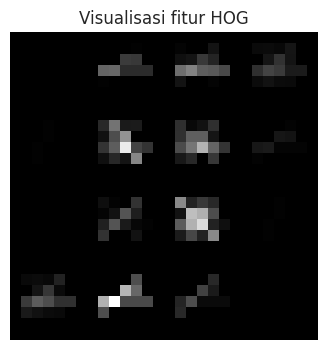

,Fitur,Dimensi,Val accuracy,Waktu (detik)
2,HOG,324,0.9715,9.008255
0,Raw pixel,784,0.9630,13.738666
1,PCA 95%,152,0.9570,7.038669


In [7]:
def extract_hog_features(images):
    output = []
    for image in images:
        output.append(hog(
            image,
            orientations=9,
            pixels_per_cell=(7, 7),
            cells_per_block=(2, 2),
            block_norm='L2-Hys',
            visualize=False,
            feature_vector=True,
        ))
    return np.asarray(output, dtype='float32')

start = timer_start()
Xf_train_hog = extract_hog_features(Xf_train.reshape(-1, 28, 28))
Xf_val_hog = extract_hog_features(Xf_val.reshape(-1, 28, 28))
hog_time = time.perf_counter() - start
hog_model, hog_history, train_time, hog_epoch = fit_model(
    Xf_train_hog, yf_train, Xf_val_hog, yf_val, hidden=(128,), epochs=8
)
feature_results.append({
    'Fitur': 'HOG', 'Dimensi': Xf_train_hog.shape[1],
    'Val accuracy': max(hog_history.history['val_accuracy']),
    'Waktu (detik)': hog_time + train_time,
})
feature_models['HOG'] = hog_model
print('HOG selesai:', Xf_train_hog.shape[1], 'fitur')

hog_visual = hog(Xf_train[0].reshape(28, 28), orientations=9,
                 pixels_per_cell=(7, 7), cells_per_block=(2, 2),
                 block_norm='L2-Hys', visualize=True)
plt.figure(figsize=(4, 4))
plt.imshow(hog_visual[1], cmap='gray')
plt.title('Visualisasi fitur HOG')
plt.axis('off')
plt.show()

feature_table = pd.DataFrame(feature_results).sort_values('Val accuracy', ascending=False)
display(feature_table)


### Interpretasi Pemilihan Fitur

Gunakan tabel hasil aktual di atas untuk membandingkan akurasi, dimensi, dan waktu. Raw pixel biasanya memberikan performa kuat pada MNIST karena posisi digit relatif konsisten. PCA mengurangi jumlah fitur dan HOG menekankan bentuk/tepi, tetapi keduanya dapat kehilangan sebagian informasi intensitas piksel.


## 4. Eksperimen Arsitektur ANN

Eksperimen berikut memakai raw pixel dan membandingkan jumlah neuron/layer hidden. Semua model menggunakan ReLU, Adam, batch size 128, serta callback EarlyStopping dan ReduceLROnPlateau.


1 layer - 128 selesai
2 layer - 256-128 selesai
2 layer - 512-256 selesai
3 layer - 512-256-128 selesai


,Arsitektur,Val accuracy,Val loss terbaik,Epoch terbaik,Parameter,Waktu (detik)
3,3 layer - 512-256-128,0.983833,0.070038,6,567434,36.531347
2,2 layer - 512-256,0.983500,0.067093,6,535818,32.755167
1,2 layer - 256-128,0.981333,0.070719,8,235146,23.606445
0,1 layer - 128,0.979167,0.072471,12,101770,17.539528


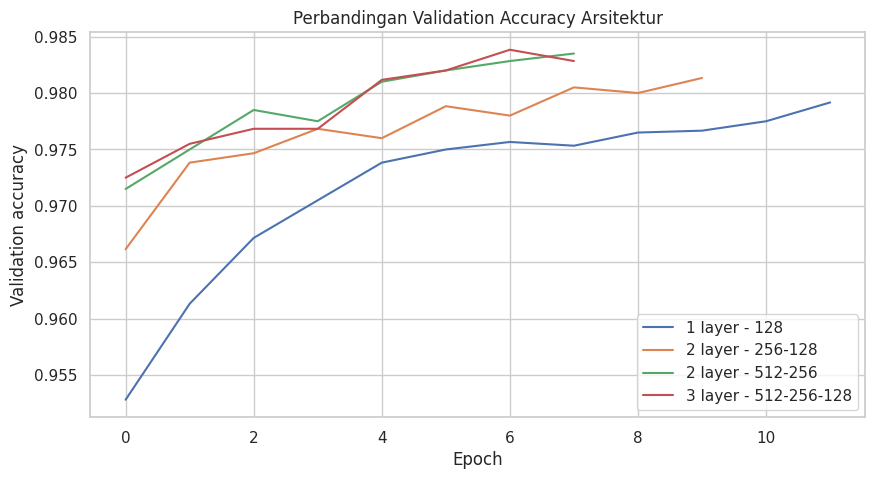

Arsitektur terbaik sementara: 3 layer - 512-256-128 (512, 256, 128)


In [8]:
architectures = {
    '1 layer - 128': (128,),
    '2 layer - 256-128': (256, 128),
    '2 layer - 512-256': (512, 256),
    '3 layer - 512-256-128': (512, 256, 128),
}

architecture_results = []
architecture_histories = {}
architecture_models = {}
for name, hidden in architectures.items():
    model, history, elapsed, best_epoch = fit_model(
        X_train_flat, y_train, X_val_flat, y_val,
        hidden=hidden, activation='relu', dropout=0.0, epochs=12
    )
    architecture_models[name] = model
    architecture_histories[name] = history
    architecture_results.append({
        'Arsitektur': name,
        'Val accuracy': max(history.history['val_accuracy']),
        'Val loss terbaik': min(history.history['val_loss']),
        'Epoch terbaik': best_epoch,
        'Parameter': model.count_params(),
        'Waktu (detik)': elapsed,
    })
    print(name, 'selesai')

architecture_table = pd.DataFrame(architecture_results).sort_values('Val accuracy', ascending=False)
display(architecture_table)

plt.figure(figsize=(10, 5))
for name, history in architecture_histories.items():
    plt.plot(history.history['val_accuracy'], label=name)
plt.title('Perbandingan Validation Accuracy Arsitektur')
plt.xlabel('Epoch')
plt.ylabel('Validation accuracy')
plt.legend()
plt.show()

best_arch_name = architecture_table.iloc[0]['Arsitektur']
best_arch = architectures[best_arch_name]
print('Arsitektur terbaik sementara:', best_arch_name, best_arch)


## 5. Eksperimen Fungsi Aktivasi

ReLU, tanh, dan sigmoid dibandingkan pada arsitektur terbaik. ReLU biasanya lebih cepat untuk jaringan dense karena mengurangi masalah vanishing gradient, sedangkan sigmoid pada hidden layer dapat belajar lebih lambat.


relu selesai
tanh selesai
sigmoid selesai


,Aktivasi,Val accuracy,Val loss terbaik,Epoch terbaik,Waktu (detik)
1,tanh,0.985167,0.059145,10,53.169922
0,relu,0.984333,0.067316,5,33.049631
2,sigmoid,0.979667,0.076257,12,51.418042


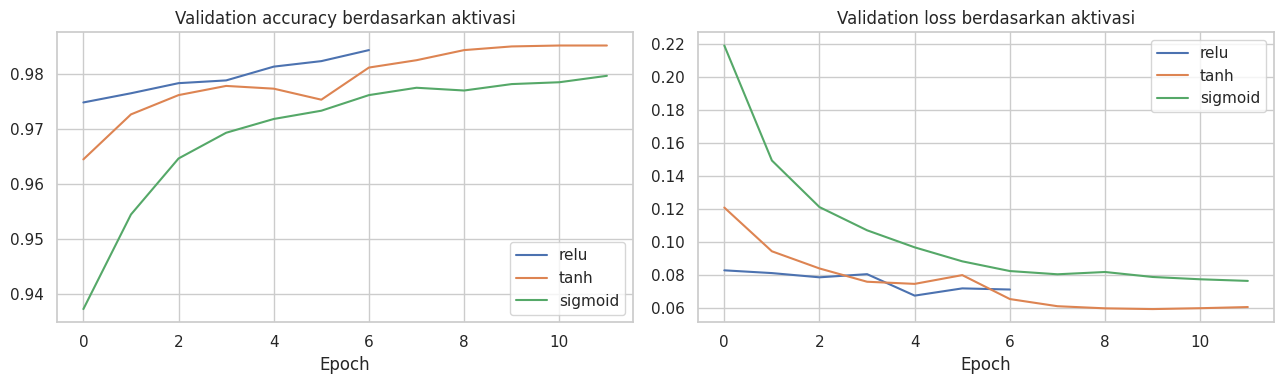

Aktivasi terbaik sementara: tanh


In [9]:
activation_results = []
activation_histories = {}
activation_models = {}
for activation in ['relu', 'tanh', 'sigmoid']:
    model, history, elapsed, best_epoch = fit_model(
        X_train_flat, y_train, X_val_flat, y_val,
        hidden=best_arch, activation=activation, epochs=12
    )
    activation_models[activation] = model
    activation_histories[activation] = history
    activation_results.append({
        'Aktivasi': activation,
        'Val accuracy': max(history.history['val_accuracy']),
        'Val loss terbaik': min(history.history['val_loss']),
        'Epoch terbaik': best_epoch,
        'Waktu (detik)': elapsed,
    })
    print(activation, 'selesai')

activation_table = pd.DataFrame(activation_results).sort_values('Val accuracy', ascending=False)
display(activation_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for activation, history in activation_histories.items():
    axes[0].plot(history.history['val_accuracy'], label=activation)
    axes[1].plot(history.history['val_loss'], label=activation)
axes[0].set_title('Validation accuracy berdasarkan aktivasi')
axes[1].set_title('Validation loss berdasarkan aktivasi')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.legend()
plt.tight_layout()
plt.show()

best_activation = activation_table.iloc[0]['Aktivasi']
print('Aktivasi terbaik sementara:', best_activation)


## 6. Model Final

Model final menggunakan kombinasi arsitektur dan aktivasi terbaik dari eksperimen sebelumnya. Validation set tetap dipakai untuk EarlyStopping; test set baru digunakan pada bagian evaluasi berikutnya.


Arsitektur final: (512, 256, 128)
Aktivasi final: tanh
Epoch terbaik: 7
Waktu training: 41.86 detik


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,702,304 (6.49 MB)

 Trainable params: 567,434 (2.16 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,134,870 (4.33 MB)

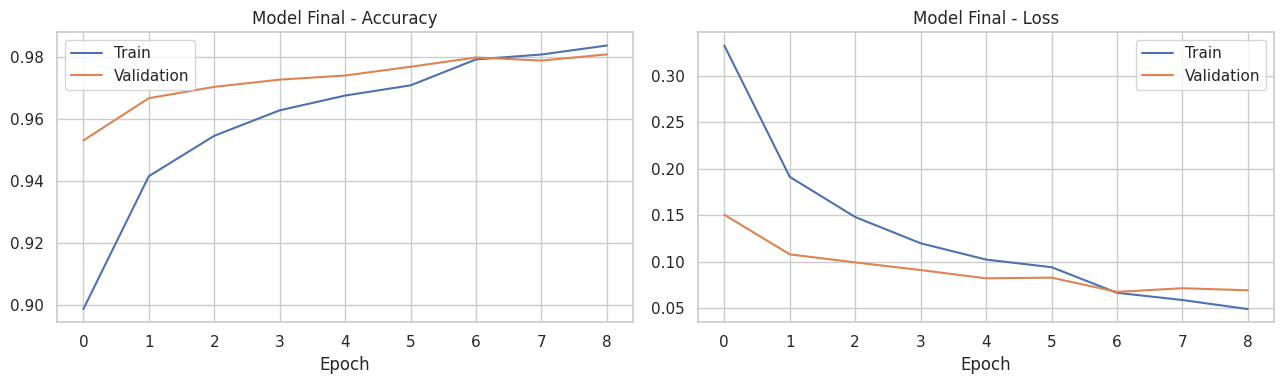

In [10]:
final_model, final_history, final_time, final_best_epoch = fit_model(
    X_train_flat, y_train, X_val_flat, y_val,
    hidden=best_arch, activation=best_activation, dropout=0.2,
    epochs=20, batch_size=128
)
print('Arsitektur final:', best_arch)
print('Aktivasi final:', best_activation)
print('Epoch terbaik:', final_best_epoch)
print('Waktu training:', round(final_time, 2), 'detik')
final_model.summary()
history_plot(final_history, 'Model Final')


## 7. Evaluasi Model pada Data Test

Metrik yang digunakan : accuracy, precision, recall, F1-score, dan confusion matrix.



In [11]:
test_loss, test_accuracy = final_model.evaluate(X_test_flat, y_test, verbose=0)
y_test_prob = final_model.predict(X_test_flat, verbose=0)
y_test_pred = np.argmax(y_test_prob, axis=1)

print('Test loss    :', round(test_loss, 5))
print('Test accuracy:', round(test_accuracy, 5))

report = classification_report(y_test, y_test_pred, output_dict=True)
report_table = pd.DataFrame(report).T
display(report_table.round(4))


Test loss    : 0.07655
Test accuracy: 0.9767


,precision,recall,f1-score,support
0,0.9797,0.9867,0.9832,980.0000
1,0.9903,0.9894,0.9899,1135.0000
2,0.9721,0.9787,0.9754,1032.0000
3,0.9696,0.9802,0.9749,1010.0000
4,0.9747,0.9796,0.9771,982.0000
5,0.9841,0.9697,0.9768,892.0000
6,0.9721,0.9812,0.9766,958.0000
7,0.9784,0.9698,0.9741,1028.0000
8,0.9693,0.9713,0.9703,974.0000
9,0.9758,0.9584,0.9670,1009.0000


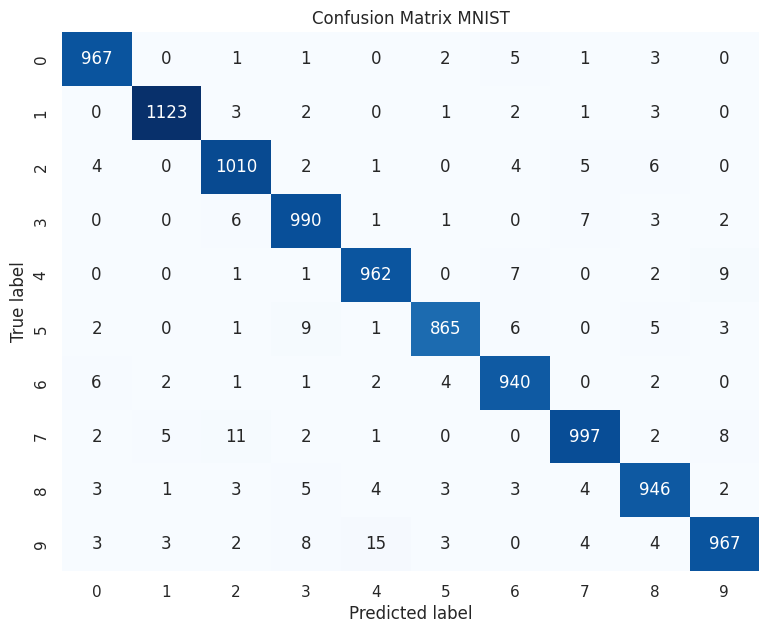

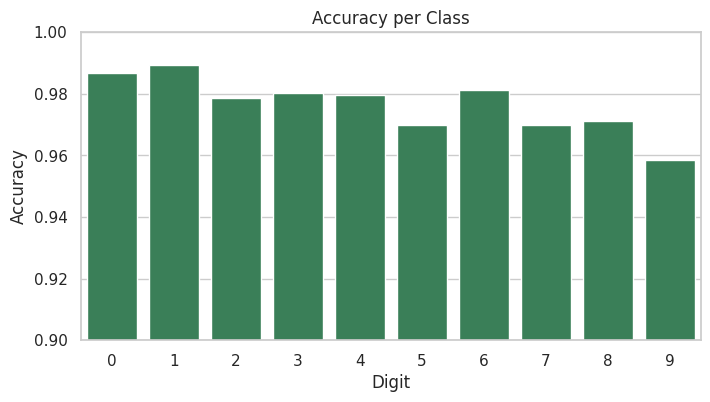

,Jumlah salah,Label asli,Prediksi
0,15,9,4
1,11,7,2
2,9,5,3
3,9,4,9
4,8,9,3
5,8,7,9
6,7,4,6
7,7,3,7
8,6,6,0
9,6,5,6


In [12]:
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix MNIST')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.show()

per_class_accuracy = cm.diagonal() / cm.sum(axis=1)
plt.figure(figsize=(8, 4))
sns.barplot(x=np.arange(10), y=per_class_accuracy, color='seagreen')
plt.ylim(0.9, 1.0)
plt.title('Accuracy per Class')
plt.xlabel('Digit')
plt.ylabel('Accuracy')
plt.show()

confusions = []
for true_label in range(10):
    for pred_label in range(10):
        if true_label != pred_label:
            confusions.append((cm[true_label, pred_label], true_label, pred_label))
confusion_table = pd.DataFrame(
    sorted(confusions, reverse=True)[:10],
    columns=['Jumlah salah', 'Label asli', 'Prediksi']
)
display(confusion_table)


## 8. Analisis Kesalahan

Contoh berikut membantu melihat digit yang bentuknya ambigu. Kesalahan yang umum pada MNIST biasanya melibatkan pasangan seperti 4–9, 3–5, 7–1, atau 2–7, tergantung hasil training.


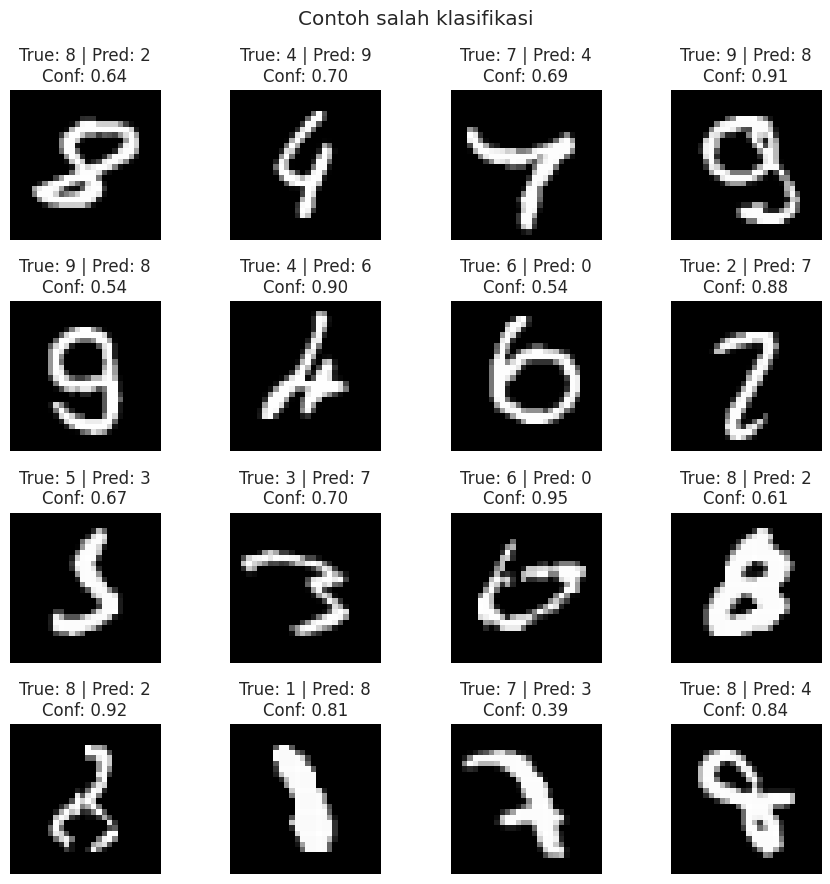

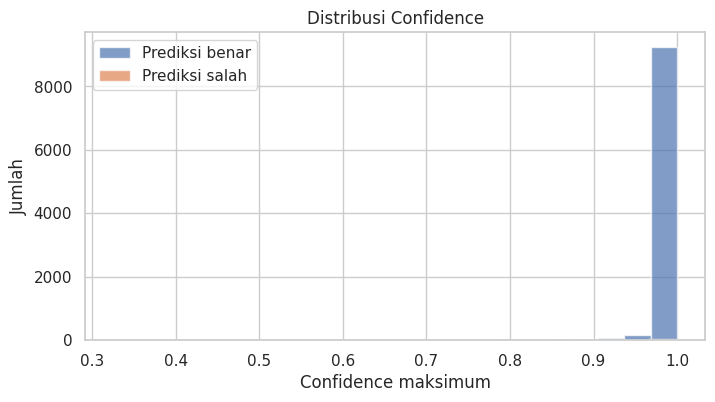

In [13]:
wrong_idx = np.where(y_test_pred != y_test)[0]
show_idx = wrong_idx[:16]
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for ax, idx in zip(axes.ravel(), show_idx):
    ax.imshow(X_test_img[idx], cmap='gray')
    pred = y_test_pred[idx]
    confidence = y_test_prob[idx, pred]
    ax.set_title(f'True: {y_test[idx]} | Pred: {pred}\nConf: {confidence:.2f}')
    ax.axis('off')
plt.suptitle('Contoh salah klasifikasi')
plt.tight_layout()
plt.show()

correct_conf = np.max(y_test_prob[y_test_pred == y_test], axis=1)
wrong_conf = np.max(y_test_prob[y_test_pred != y_test], axis=1)
plt.figure(figsize=(8, 4))
plt.hist(correct_conf, bins=20, alpha=0.7, label='Prediksi benar')
plt.hist(wrong_conf, bins=20, alpha=0.7, label='Prediksi salah')
plt.xlabel('Confidence maksimum')
plt.ylabel('Jumlah')
plt.title('Distribusi Confidence')
plt.legend()
plt.show()


## 9. Simpan, Muat, dan Demo Prediksi

Format `.keras` adalah format penyimpanan Keras modern. Model dimuat ulang untuk memastikan artefak yang disimpan dapat digunakan kembali.


Model tersimpan: mnist_ann.keras
Akurasi setelah load ulang: 0.9767


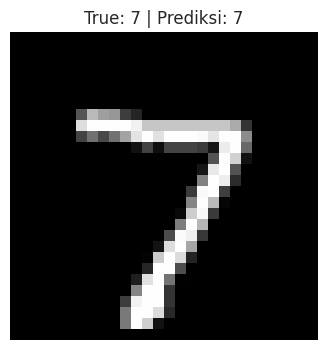

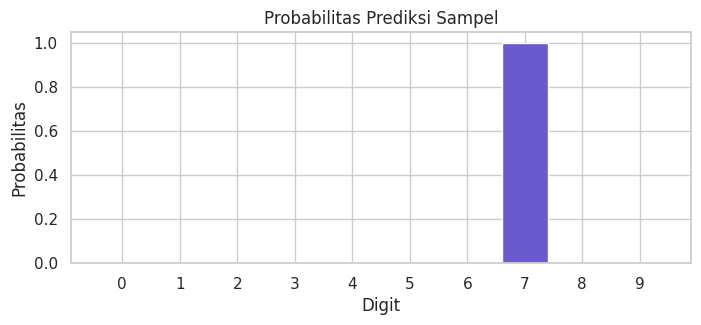

In [14]:
MODEL_PATH = 'mnist_ann.keras'
final_model.save(MODEL_PATH)
loaded_model = keras.models.load_model(MODEL_PATH)
loaded_loss, loaded_acc = loaded_model.evaluate(X_test_flat, y_test, verbose=0)
print('Model tersimpan:', MODEL_PATH)
print('Akurasi setelah load ulang:', round(loaded_acc, 5))

demo_idx = 0
demo_prob = loaded_model.predict(X_test_flat[demo_idx:demo_idx + 1], verbose=0)[0]
demo_pred = int(np.argmax(demo_prob))
plt.figure(figsize=(4, 4))
plt.imshow(X_test_img[demo_idx], cmap='gray')
plt.title(f'True: {y_test[demo_idx]} | Prediksi: {demo_pred}')
plt.axis('off')
plt.show()

plt.figure(figsize=(8, 3))
plt.bar(np.arange(10), demo_prob, color='slateblue')
plt.xticks(np.arange(10))
plt.xlabel('Digit')
plt.ylabel('Probabilitas')
plt.title('Probabilitas Prediksi Sampel')
plt.show()


# [TAMBAHAN A] Eksperimen Dropout

Bagian ini bukan persyaratan minimum tugas. Dropout dibandingkan untuk melihat pengaruh regularisasi terhadap gap accuracy train dan validation.


In [15]:
dropout_results = []
dropout_histories = {}
for dropout in [0.0, 0.2, 0.3]:
    model, history, elapsed, best_epoch = fit_model(
        X_train_flat, y_train, X_val_flat, y_val,
        hidden=best_arch, activation=best_activation,
        dropout=dropout, epochs=10
    )
    dropout_histories[dropout] = history
    dropout_results.append({
        'Dropout': dropout,
        'Train accuracy terakhir': history.history['accuracy'][-1],
        'Val accuracy terbaik': max(history.history['val_accuracy']),
        'Waktu (detik)': elapsed,
    })
dropout_table = pd.DataFrame(dropout_results)
display(dropout_table)


,Dropout,Train accuracy terakhir,Val accuracy terbaik,Waktu (detik)
0,0.0,0.999778,0.985000,42.150296
1,0.2,0.985963,0.980500,47.482483
2,0.3,0.977778,0.979667,48.429724


# [TAMBAHAN B] Learning Rate dan Batch Size

Bagian ini menguji pengaruh learning rate dan batch size secara ringan. Nilai yang lebih kecil biasanya membuat pembaruan bobot lebih hati-hati, sedangkan batch size memengaruhi stabilitas dan kecepatan training.


In [16]:
tuning_results = []
for learning_rate, batch_size in [(1e-3, 128), (5e-4, 128), (1e-4, 128), (1e-3, 64), (1e-3, 256)]:
    model, history, elapsed, best_epoch = fit_model(
        Xf_train, yf_train, Xf_val, yf_val,
        hidden=(128,), activation='relu', epochs=8,
        batch_size=batch_size, learning_rate=learning_rate
    )
    tuning_results.append({
        'Learning rate': learning_rate,
        'Batch size': batch_size,
        'Val accuracy terbaik': max(history.history['val_accuracy']),
        'Epoch terbaik': best_epoch,
        'Waktu (detik)': elapsed,
    })
tuning_table = pd.DataFrame(tuning_results).sort_values('Val accuracy terbaik', ascending=False)
display(tuning_table)


,Learning rate,Batch size,Val accuracy terbaik,Epoch terbaik,Waktu (detik)
3,0.0010,64,0.9615,8,8.895642
0,0.0010,128,0.9580,8,5.810133
4,0.0010,256,0.9565,8,3.798019
1,0.0005,128,0.9520,8,4.770738
2,0.0001,128,0.9215,8,5.693656


# [TAMBAHAN C] ROC-AUC Multiclass

ROC-AUC one-vs-rest digunakan sebagai metrik tambahan. Untuk tugas utama, classification report dan confusion matrix tetap menjadi evaluasi utama.


In [17]:
y_test_onehot = keras.utils.to_categorical(y_test, num_classes=10)
auc_macro = roc_auc_score(y_test_onehot, y_test_prob, multi_class='ovr', average='macro')
print('ROC-AUC macro one-vs-rest:', round(auc_macro, 5))


ROC-AUC macro one-vs-rest: 0.99965


# [TAMBAHAN D] Ringkasan Semua Eksperimen


,Eksperimen,Akurasi,Waktu (detik)
8,Aktivasi - tanh,0.985167,53.169922
7,Aktivasi - relu,0.984333,33.049631
6,Arsitektur - 3 layer - 512-256-128,0.983833,36.531347
5,Arsitektur - 2 layer - 512-256,0.983500,32.755167
4,Arsitektur - 2 layer - 256-128,0.981333,23.606445
9,Aktivasi - sigmoid,0.979667,51.418042
3,Arsitektur - 1 layer - 128,0.979167,17.539528
2,Fitur - HOG,0.971500,9.008255
0,Fitur - Raw pixel,0.963000,13.738666
1,Fitur - PCA 95%,0.957000,7.038669


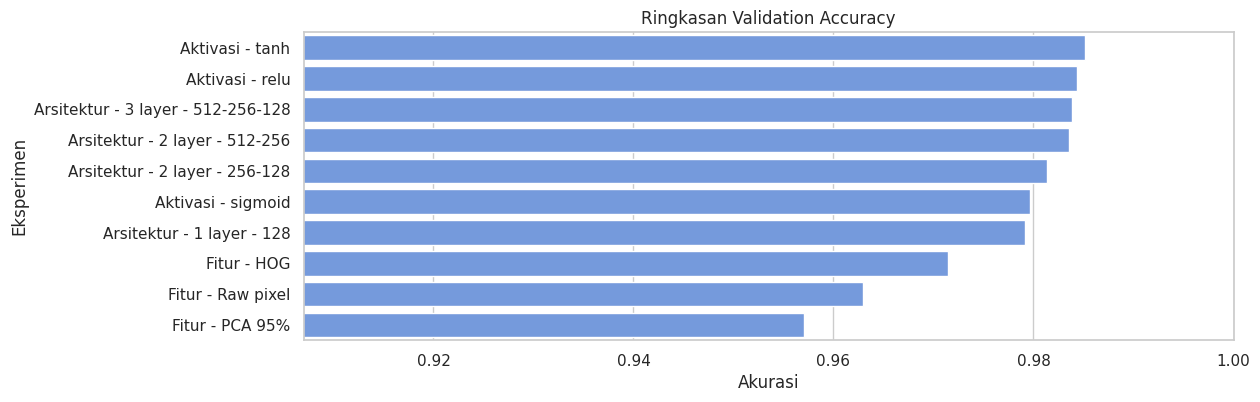

In [18]:
summary_rows = []
for row in feature_results:
    summary_rows.append({'Eksperimen': 'Fitur - ' + row['Fitur'], 'Akurasi': row['Val accuracy'], 'Waktu (detik)': row['Waktu (detik)']})
for row in architecture_results:
    summary_rows.append({'Eksperimen': 'Arsitektur - ' + row['Arsitektur'], 'Akurasi': row['Val accuracy'], 'Waktu (detik)': row['Waktu (detik)']})
for row in activation_results:
    summary_rows.append({'Eksperimen': 'Aktivasi - ' + row['Aktivasi'], 'Akurasi': row['Val accuracy'], 'Waktu (detik)': row['Waktu (detik)']})
summary_table = pd.DataFrame(summary_rows).sort_values('Akurasi', ascending=False)
display(summary_table)

plt.figure(figsize=(12, max(4, len(summary_table) * 0.3)))
sns.barplot(data=summary_table, x='Akurasi', y='Eksperimen', color='cornflowerblue')
plt.xlim(max(0, summary_table['Akurasi'].min() - 0.05), 1.0)
plt.title('Ringkasan Validation Accuracy')
plt.show()


# [TAMBAHAN E] Uji Ketahanan terhadap Pergeseran dan Rotasi

MNIST test set dimodifikasi dengan translasi kecil dan rotasi ringan. Eksperimen ini menunjukkan apakah model dense ANN tetap kuat ketika posisi atau orientasi digit berubah.


,Kondisi,Accuracy
0,Asli,0.975
1,Geser 1 piksel,0.901
2,Rotasi 10 derajat,0.957


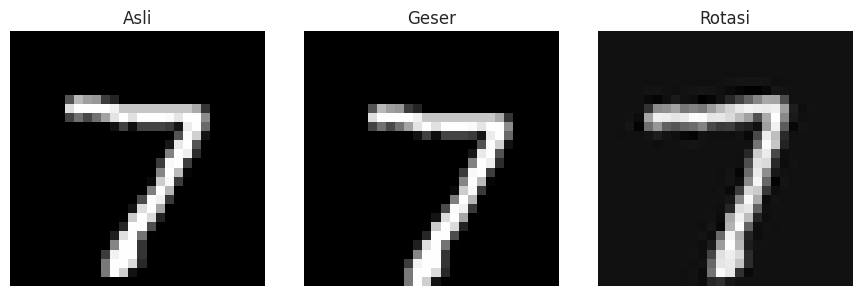

In [19]:
robust_images = X_test_img[:1000].astype('float32')
robust_labels = y_test[:1000]

shifted = np.asarray([shift(img, shift=(1, 1), mode='constant') for img in robust_images])
rotated = np.asarray([rotate(img, angle=10, reshape=False, mode='constant') for img in robust_images])

def robust_accuracy(images):
    flat = (images / 255.0).reshape(len(images), -1)
    pred = np.argmax(loaded_model.predict(flat, verbose=0), axis=1)
    return np.mean(pred == robust_labels)

robust_table = pd.DataFrame([
    {'Kondisi': 'Asli', 'Accuracy': robust_accuracy(robust_images)},
    {'Kondisi': 'Geser 1 piksel', 'Accuracy': robust_accuracy(shifted)},
    {'Kondisi': 'Rotasi 10 derajat', 'Accuracy': robust_accuracy(rotated)},
])
display(robust_table)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, image, title in zip(axes, [robust_images[0], shifted[0], rotated[0]], ['Asli', 'Geser', 'Rotasi']):
    ax.imshow(image, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()
